In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [ ]:
# 1. Read dataset
df = pd.read_csv("uber.csv")
print(df.head())
print(df.isnull().sum())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [ ]:
# 2. Preprocess dataset
df = df.dropna()
df = df.drop_duplicates()
df = df[(df["fare_amount"] > 0) &
(df["passenger_count"] > 0)]
# Remove invalid coordinates
df = df[
    df["pickup_longitude"].between(-180, 180) &
    df["dropoff_longitude"].between(-180, 180) &
    df["pickup_latitude"].between(-90, 90) &
    df["dropoff_latitude"].between(-90, 90)
]
# Convert pickup time into numeric features
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)
df = df.dropna(subset=["pickup_datetime"])
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month

In [ ]:
# 3. Identify outliers using IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1
outliers = df[
(df["fare_amount"] < Q1 - 1.5 * IQR) |
(df["fare_amount"] > Q3 + 1.5 * IQR)
]
print("Number of fare outliers:", len(outliers))
# Remove fare outliers
df = df[
    df["fare_amount"].between(
        Q1- 1.5 * IQR, Q3 + 1.5 * IQR
)
]

Number of fare outliers: 17120


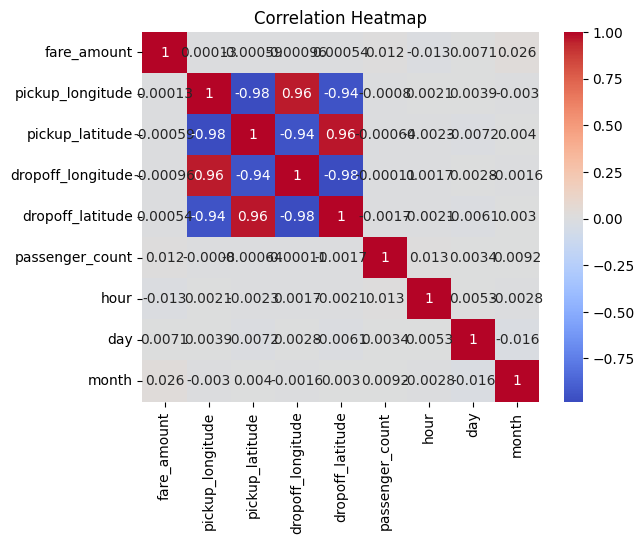

In [ ]:
# 4. Check correlation
columns = [
"fare_amount", "pickup_longitude", "pickup_latitude",
"dropoff_longitude", "dropoff_latitude",
"passenger_count", "hour", "day", "month"
]
sns.heatmap(df[columns].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# 5. Features and target
X = df[[
"pickup_longitude", "pickup_latitude",
"dropoff_longitude", "dropoff_latitude",
"passenger_count", "hour", "day", "month"
]]
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
# 6. Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
# 7. Random Forest Regression
rf = RandomForestRegressor(
    n_estimators=100, random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

In [ ]:
# 8. Evaluate models
for name, pred in [
("Linear Regression", pred_lr),
("Random Forest", pred_rf)
]:
    print("\n", name)
    print("R2 Score:", r2_score(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))


 Linear Regression
R2 Score: 0.000830214494680348
RMSE: 4.135246791775698

 Random Forest
R2 Score: 0.7220048331881146
RMSE: 2.1812247140034398
